# Avance 2. Ingeniería de características

**Proyecto Integrador (TC5035.10) · Equipo 48 · Planograma: IA para detección de productos y ubicación**

| Integrante | Matrícula |
|---|---|
| Oscar Alberto Ramírez Anaya | A01795438 |
| Germán Eduardo Rodríguez Vázquez | A01796325 |
| Jesús Soto Medrano | A01794746 |

Profesora: Dra. Grettel Barceló Alonso · Asesor: Dr. Raúl Valente Ramírez · Patrocinador: Dr. Juan Arturo Nolazco Flores · Organización: Bnext

---

**Fase CRISP-ML(Q):** Preparación de los datos (*Data Preparation*). Este avance transforma la muestra
de imágenes proporcionada por Bnext en un conjunto de variables útiles para el aprendizaje automático:
construcción, discretización, codificación, transformación y escalamiento (sección A), selección y
extracción de características (sección B) y conclusiones de la fase (sección C).

**Manejo de datos.** Conforme al acuerdo con Bnext (`POLITICA_DATOS.md`), la libreta se ejecuta
dentro del servidor de la organización. Las imágenes no salen de esa infraestructura y la libreta
publicada contiene únicamente tablas y gráficas agregadas: no se muestran fotografías ni recortes de
producto, y los códigos de SKU se anonimizan como `SKU_01` … `SKU_35`.

## 0. Configuración

Todas las rutas se leen de variables de entorno (`PLANOGRAMA_DATA_DIR` para los datos y
`PLANOGRAMA_OUT_DIR` para las salidas tabulares y el pipeline ajustado), de modo que el código no
contiene ubicaciones del servidor. La semilla `SEED = 48` fija todo componente estocástico.

In [1]:
import os, re, time, json, warnings, pathlib
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from skimage.feature import hog, local_binary_pattern
from skimage.measure import shannon_entropy

import sklearn
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (StandardScaler, MinMaxScaler, RobustScaler, PowerTransformer,
                                   FunctionTransformer, OneHotEncoder, OrdinalEncoder,
                                   LabelEncoder, KBinsDiscretizer)
from sklearn.feature_selection import (VarianceThreshold, SelectKBest, f_classif, chi2,
                                       mutual_info_classif)
from sklearn.decomposition import PCA, FactorAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import StratifiedGroupKFold, cross_val_score
from sklearn.metrics import f1_score, accuracy_score
from sklearn.exceptions import ConvergenceWarning
from factor_analyzer.factor_analyzer import calculate_kmo, calculate_bartlett_sphericity
import joblib

SEED = 48
np.random.seed(SEED)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 100

DATA_DIR = pathlib.Path(os.environ.get('PLANOGRAMA_DATA_DIR', 'data/raw/sample'))
OUT_DIR = pathlib.Path(os.environ.get('PLANOGRAMA_OUT_DIR', 'outputs'))
OUT_DIR.mkdir(parents=True, exist_ok=True)
assert DATA_DIR.exists(), 'Definir PLANOGRAMA_DATA_DIR con la ubicación de la muestra'

print('numpy', np.__version__, '| pandas', pd.__version__, '| scikit-learn', sklearn.__version__,
      '| OpenCV', cv2.__version__)

numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1 | OpenCV 5.0.0


## 1. Datos de partida

La muestra entregada por Bnext tiene dos unidades de análisis:

- **Escenas**: fotografías de exhibidores (refrigeradores y vitrinas) en cinco tipos de toma:
  la foto original del dispositivo, el mueble recortado y el mueble aislado.
- **Recortes de producto**: imágenes de un solo producto etiquetadas con su SKU. Es el único
  subconjunto con una variable objetivo (el SKU) y por ello es el que se usa para evaluar la
  selección de características contra un modelo base.

Los códigos de SKU se reemplazan por identificadores anónimos ordenados (`SKU_01` … `SKU_35`); el
nombre de archivo solo se usa para derivar el orden temporal de captura y nunca se imprime.

In [2]:
TIPOS_TOMA = ['originales', 'refrigeradores', 'vitrinas', 'solo-refrigeradores', 'solo-vitrinas']
escenas = [(t, p) for t in TIPOS_TOMA for p in sorted((DATA_DIR / t).glob('*.jpg'))]

codigos = sorted(d.name for d in (DATA_DIR / 'skus').iterdir() if d.is_dir())
anonimo = {c: f'SKU_{i:02d}' for i, c in enumerate(codigos, start=1)}
recortes = [(anonimo[d.name], p) for d in sorted((DATA_DIR / 'skus').iterdir()) if d.is_dir()
            for p in sorted(d.glob('*.jpg'))]

inv = pd.DataFrame({'unidad': ['escenas'] * len(escenas) + ['recortes de producto'] * len(recortes),
                    'grupo': [t for t, _ in escenas] + ['skus'] * len(recortes)})
display(inv.groupby(['unidad', 'grupo']).size().rename('imágenes').to_frame())
print(f'Escenas: {len(escenas)} | Recortes: {len(recortes)} | Clases SKU: {len(codigos)}')

imágenes
unidad               grupo                        
escenas              originales                 20
                     refrigeradores             20
                     solo-refrigeradores        20
                     solo-vitrinas              20
                     vitrinas                   20
recortes de producto skus                      422

Escenas: 100 | Recortes: 422 | Clases SKU: 35


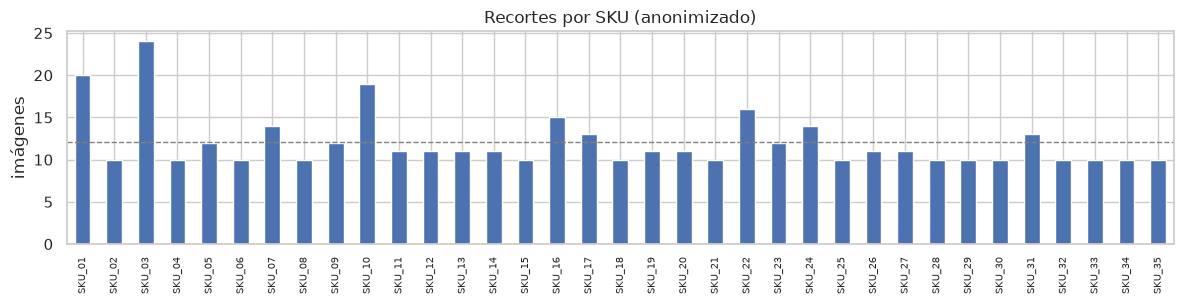

mín 10, máx 24, razón de desbalance 2.4x


In [3]:
por_sku = pd.Series([s for s, _ in recortes]).value_counts().sort_index()
fig, ax = plt.subplots(figsize=(12, 3.2))
por_sku.plot.bar(ax=ax, color='#4C72B0')
ax.set(title='Recortes por SKU (anonimizado)', xlabel='', ylabel='imágenes')
ax.axhline(por_sku.mean(), ls='--', c='gray', lw=1)
plt.xticks(fontsize=7); plt.tight_layout(); plt.show()
print(f'mín {por_sku.min()}, máx {por_sku.max()}, razón de desbalance {por_sku.max()/por_sku.min():.1f}x')

## 2. Extracción de características base

Las imágenes no son directamente utilizables por un modelo tabular, así que se convierten en vectores
de variables con significado visual. Cada familia responde a un aspecto del problema de planograma:

| Familia | Variables | Por qué |
|---|---|---|
| Geometría y archivo | ancho, alto, área, relación de aspecto, tamaño en KB | El formato del empaque (botella alta, caja, bolsa) y la resolución de captura. |
| Exposición y calidad | brillo (V de HSV), contraste (desv. estándar de grises), nitidez (varianza del Laplaciano; Pech-Pacheco et al., 2000), densidad de bordes (Canny), entropía, fracción de píxeles sub/sobreexpuestos | Las fotos de anaquel se toman en tienda con iluminación y dispositivos variables; estas variables miden si una captura es apta. |
| Color | saturación media, *colorfulness* (Hasler y Süsstrunk, 2003), momentos de color en Lab, histogramas H/S/V, fracción de blanco | El color del empaque es la señal más directa para distinguir marcas y presentaciones. Lab separa luminancia de cromaticidad. |
| Textura | histograma LBP uniforme (Ojala et al., 2002) | Describe patrones locales (texto, logotipos, relieves) con invariancia a cambios de iluminación. |
| Forma | descriptor HOG (Dalal y Triggs, 2005) sobre el recorte normalizado a 64×128 | Captura la silueta y la distribución de bordes del empaque. |

En las escenas solo se calculan geometría, exposición y color globales: el objetivo ahí es caracterizar
la calidad de captura, no identificar productos.

In [4]:
HOG_TAM = (64, 128)          # (ancho, alto) estándar de Dalal y Triggs
H_BINS, S_BINS, V_BINS = 12, 4, 4

def colorfulness(bgr):
    b, g, r = [c.astype(float) for c in cv2.split(bgr)]
    rg, yb = r - g, 0.5 * (r + g) - b
    return np.hypot(rg.std(), yb.std()) + 0.3 * np.hypot(rg.mean(), yb.mean())

def rasgos_globales(ruta):
    bgr = cv2.imread(str(ruta))
    gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
    hsv = cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV)
    h, s, v = [hsv[..., i].astype(float) for i in range(3)]
    alto, ancho = gray.shape
    # Matiz circular ponderado por saturación: un color gris no aporta información de matiz
    ang = np.deg2rad(h * 2.0); w = s / 255.0 + 1e-9
    return bgr, gray, hsv, {
        'ancho': ancho, 'alto': alto, 'area_px': ancho * alto, 'aspecto': alto / ancho,
        'archivo_kb': ruta.stat().st_size / 1024,
        'brillo': v.mean(), 'contraste': gray.std(),
        'nitidez': cv2.Laplacian(gray, cv2.CV_64F).var(),
        'densidad_bordes': (cv2.Canny(gray, 100, 200) > 0).mean(),
        'entropia': shannon_entropy(gray),
        'frac_subexp': (v < 15).mean(), 'frac_sobreexp': (v > 245).mean(),
        'saturacion': s.mean(), 'colorfulness': colorfulness(bgr),
        'frac_blanco': ((s < 30) & (v > 200)).mean(),
        'hue_x': np.average(np.cos(ang), weights=w), 'hue_y': np.average(np.sin(ang), weights=w),
    }

def rasgos_recorte(ruta):
    bgr, gray, hsv, f = rasgos_globales(ruta)
    lab = cv2.cvtColor(bgr, cv2.COLOR_BGR2LAB).reshape(-1, 3).astype(float)
    for i, canal in enumerate('Lab'):
        f[f'{canal}_media'] = lab[:, i].mean(); f[f'{canal}_desv'] = lab[:, i].std()
        f[f'{canal}_sesgo'] = stats.skew(lab[:, i])
    sat = hsv[..., 1] > 40   # el histograma de matiz solo con píxeles cromáticos
    hh = np.histogram(hsv[..., 0][sat], bins=H_BINS, range=(0, 180))[0]
    f.update({f'hist_h{i:02d}': x / max(hh.sum(), 1) for i, x in enumerate(hh)})
    for canal, n in ((1, S_BINS), (2, V_BINS)):
        hc = np.histogram(hsv[..., canal], bins=n, range=(0, 256))[0] / hsv[..., canal].size
        f.update({f'hist_{"sv"[canal - 1]}{i}': x for i, x in enumerate(hc)})
    g128 = cv2.resize(gray, (128, 128), interpolation=cv2.INTER_AREA)
    lbp = local_binary_pattern(g128, P=8, R=1, method='uniform')
    hl = np.histogram(lbp, bins=10, range=(0, 10))[0] / lbp.size
    f.update({f'lbp_{i}': x for i, x in enumerate(hl)})
    ghog = cv2.resize(gray, HOG_TAM, interpolation=cv2.INTER_AREA)
    vec = hog(ghog, orientations=9, pixels_per_cell=(16, 16), cells_per_block=(2, 2),
              block_norm='L2-Hys')
    f.update({f'hog_{i:03d}': x for i, x in enumerate(vec)})
    return f

t0 = time.time()
df_esc = pd.DataFrame([{'tipo_toma': t, **rasgos_globales(p)[3]} for t, p in escenas])
df_rec = pd.DataFrame([{'sku': s, **rasgos_recorte(p)} for s, p in recortes])
print(f'Extracción en {time.time() - t0:.1f} s | escenas {df_esc.shape} | recortes {df_rec.shape}')

Extracción en 51.7 s | escenas (100, 18) | recortes (422, 813)


In [5]:
FAMILIAS = {
    'geometría y archivo': ['ancho', 'alto', 'area_px', 'aspecto', 'archivo_kb'],
    'exposición y calidad': ['brillo', 'contraste', 'nitidez', 'densidad_bordes', 'entropia',
                             'frac_subexp', 'frac_sobreexp'],
    'color global': ['saturacion', 'colorfulness', 'frac_blanco', 'hue_x', 'hue_y']
                    + [c for c in df_rec if c[:2] in ('L_', 'a_', 'b_')],
    'histogramas HSV': [c for c in df_rec if c.startswith('hist_')],
    'textura LBP': [c for c in df_rec if c.startswith('lbp_')],
    'forma HOG': [c for c in df_rec if c.startswith('hog_')],
}
display(pd.Series({k: len(v) for k, v in FAMILIAS.items()}, name='variables').to_frame())
print('Valores faltantes en recortes:', int(df_rec.isna().sum().sum()),
      '| en escenas:', int(df_esc.isna().sum().sum()))

,variables
geometría y archivo,5
exposición y calidad,7
color global,14
histogramas HSV,20
textura LBP,10
forma HOG,756


Valores faltantes en recortes: 0 | en escenas: 0


# A. Ingeniería de características

## 3. Construcción de nuevas características

Se derivan variables nuevas a partir de las existentes con base en el conocimiento del dominio de
captura en tienda. Todas se calculan con constantes fijas (no con estadísticos del conjunto), por lo
que no introducen fuga de información entre entrenamiento y prueba.

| Variable nueva | Definición | Justificación |
|---|---|---|
| `megapixeles` | área / 10⁶ | Unidad interpretable de resolución del dispositivo. |
| `kb_por_mp` | tamaño del archivo / megapíxeles | Proxy de detalle y compresión: a igual resolución, un JPEG pesa más si tiene más textura y menos si está borroso o sobrecomprimido. |
| `nitidez_por_borde` | nitidez / densidad de bordes | La varianza del Laplaciano crece con la cantidad de bordes; normalizarla separa “imagen con mucho contenido” de “imagen enfocada”. |
| `exposicion_ok` | 1 − \|brillo − 128\| / 128 | Distancia a una exposición centrada; 1 es ideal, 0 es negro o blanco puro. |
| `indice_calidad` | promedio de `exposicion_ok`, nitidez acotada log(1+n)/log(501) y contraste acotado (contraste/64) | Resume en una sola variable si la captura es apta para reconocimiento. |
| `flag_borrosa` | nitidez < 100 | Umbral empírico habitual para la varianza del Laplaciano; marca capturas que conviene repetir. |
| `flag_oscura`, `flag_sobreexpuesta` | brillo < 60; más del 10 % de píxeles con V > 245 | Iluminación deficiente de refrigeradores y reflejos en vitrinas. |
| `hue_x`, `hue_y` | coseno y seno del matiz medio ponderado por saturación | El matiz es una variable **circular** (0° y 360° son el mismo rojo); usar el ángulo crudo haría que rojos opuestos en la escala parezcan lejanos. |

In [6]:
def construir(df):
    d = df.copy()
    d['megapixeles'] = d['area_px'] / 1e6
    d['kb_por_mp'] = d['archivo_kb'] / d['megapixeles']
    d['nitidez_por_borde'] = d['nitidez'] / (d['densidad_bordes'] + 1e-3)
    d['exposicion_ok'] = 1 - (d['brillo'] - 128).abs() / 128
    d['indice_calidad'] = (d['exposicion_ok']
                           + np.minimum(1, np.log1p(d['nitidez']) / np.log(501))
                           + np.minimum(1, d['contraste'] / 64)) / 3
    d['flag_borrosa'] = (d['nitidez'] < 100).astype(int)
    d['flag_oscura'] = (d['brillo'] < 60).astype(int)
    d['flag_sobreexpuesta'] = (d['frac_sobreexp'] > 0.10).astype(int)
    return d

df_esc = construir(df_esc)
df_rec = construir(df_rec)
NUEVAS = ['megapixeles', 'kb_por_mp', 'nitidez_por_borde', 'exposicion_ok', 'indice_calidad']
FLAGS = ['flag_borrosa', 'flag_oscura', 'flag_sobreexpuesta']

resumen = df_esc.groupby('tipo_toma')[['megapixeles', 'indice_calidad'] + FLAGS].mean().round(3)
display(resumen.loc[TIPOS_TOMA])
print('Recortes con alguna alerta de calidad:',
      f"{(df_rec[FLAGS].sum(axis=1) > 0).mean():.1%}",
      '| detalle:', df_rec[FLAGS].mean().round(3).to_dict())

,megapixeles,indice_calidad,flag_borrosa,flag_oscura,flag_sobreexpuesta
tipo_toma,,,,,
originales,2.074,0.971,0.0,0.0,0.00
refrigeradores,1.490,0.935,0.0,0.0,0.00
vitrinas,1.428,0.938,0.0,0.0,0.00
solo-refrigeradores,0.785,0.906,0.0,0.0,0.15
solo-vitrinas,0.550,0.832,0.0,0.0,0.00


Recortes con alguna alerta de calidad: 55.9% | detalle: {'flag_borrosa': 0.0, 'flag_oscura': 0.0, 'flag_sobreexpuesta': 0.559}


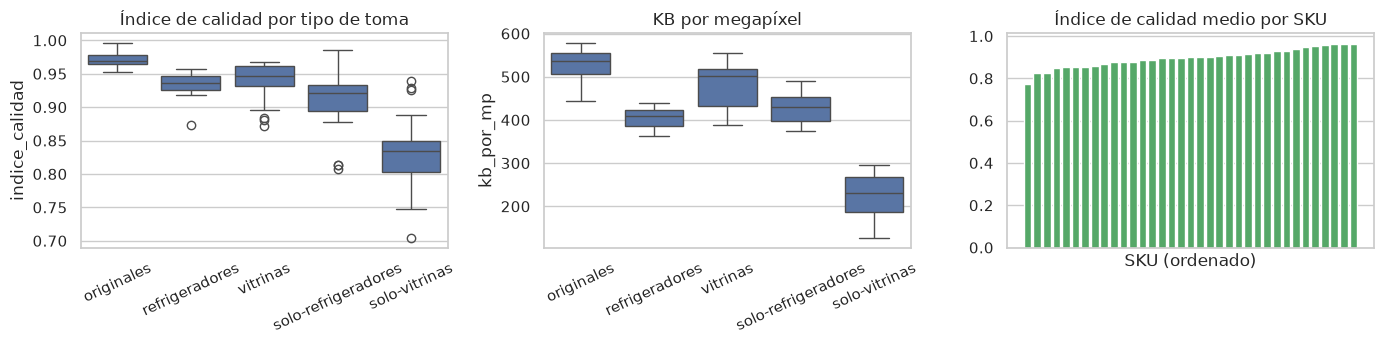

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
sns.boxplot(data=df_esc, x='tipo_toma', y='indice_calidad', order=TIPOS_TOMA, ax=axes[0])
axes[0].set(title='Índice de calidad por tipo de toma', xlabel=''); axes[0].tick_params(axis='x', rotation=25)
sns.boxplot(data=df_esc, x='tipo_toma', y='kb_por_mp', order=TIPOS_TOMA, ax=axes[1])
axes[1].set(title='KB por megapíxel', xlabel=''); axes[1].tick_params(axis='x', rotation=25)
q = df_rec.groupby('sku')['indice_calidad'].mean().sort_values()
axes[2].bar(range(len(q)), q.values, color='#55A868')
axes[2].set(title='Índice de calidad medio por SKU', xticks=[], xlabel='SKU (ordenado)')
plt.tight_layout(); plt.show()

**Interpretación.** El índice de calidad separa con claridad los tipos de toma: la foto original del dispositivo (2.07 MP) obtiene el índice más alto (0.97) y el mueble aislado de vitrina (0.55 MP) el más bajo (0.83). Cada recorte sucesivo pierde resolución y contraste. Ninguna escena ni recorte se marca como borroso u oscuro. En cambio, 55.9 % de los recortes de producto activan `flag_sobreexpuesta`: los empaques con etiquetas blancas y los reflejos del refrigerador superan con facilidad el 10 % de píxeles casi blancos. Por eso el umbral de sobreexposición, que funciona para escenas completas, debe recalibrarse por producto antes de usarse como alerta. Esa es una decisión que se llevará a la fase de modelado. Lo mismo ocurre con el umbral de nitidez de 100: está pensado para fotografías completas, y en recortes pequeños y nítidos la varianza del Laplaciano es mucho mayor (cuartiles de 1 869 a 4 563), así que nunca se activa.

## 4. Discretización (*binning*)

Se discretizan tres variables continuas, cada una con un criterio distinto según lo que se quiere
representar:

- **Brillo → `nivel_iluminacion`** (cortes de dominio 0–60–190–255: oscuro, normal, claro). Los
  cortes provienen de la definición de los indicadores de exposición y son interpretables para el
  personal de tienda; un corte por cuantiles cambiaría de significado con cada muestra.
- **Relación de aspecto → `formato_empaque`** (cortes de dominio: < 0.8 horizontal, 0.8–1.25
  cuadrado, 1.25–2 vertical, > 2 muy vertical). Agrupa botellas, latas, cajas y bolsas.
- **Nitidez → `nitidez_q`** (cuartiles, `KBinsDiscretizer(strategy='quantile')`). Su distribución
  es muy asimétrica; los cuartiles reparten los recortes en grupos de igual tamaño y reducen el
  efecto de los valores extremos. Los cortes se ajustan **solo con el conjunto de entrenamiento**
  (sección 6).

Las tres son ordinales y se usan además como entrada de la prueba chi-cuadrado, que requiere
variables categóricas o de conteo.

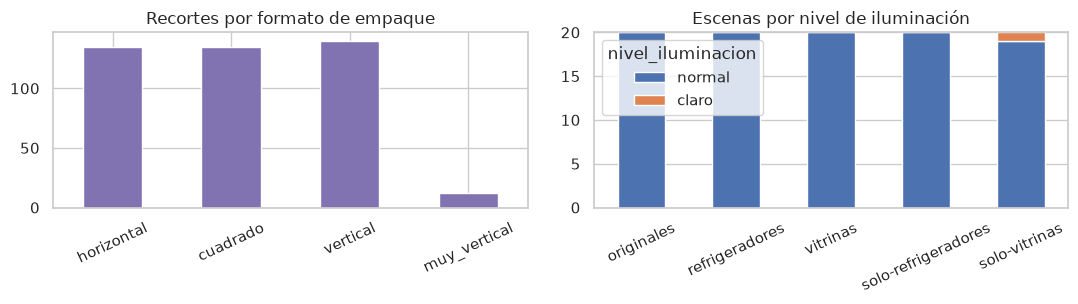

SKU con más de un formato de empaque: 18 de 35


In [8]:
def discretizar_dominio(d):
    d = d.copy()
    d['nivel_iluminacion'] = pd.cut(d['brillo'], [-np.inf, 60, 190, np.inf],
                                    labels=['oscuro', 'normal', 'claro'])
    d['formato_empaque'] = pd.cut(d['aspecto'], [-np.inf, 0.8, 1.25, 2.0, np.inf],
                                  labels=['horizontal', 'cuadrado', 'vertical', 'muy_vertical'])
    return d

df_esc = discretizar_dominio(df_esc)
df_rec = discretizar_dominio(df_rec)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
df_rec['formato_empaque'].value_counts().reindex(df_rec['formato_empaque'].cat.categories).plot.bar(
    ax=axes[0], color='#8172B2', title='Recortes por formato de empaque')
pd.crosstab(df_esc['tipo_toma'], df_esc['nivel_iluminacion']).loc[TIPOS_TOMA].plot.bar(
    stacked=True, ax=axes[1], title='Escenas por nivel de iluminación')
for a in axes: a.set_xlabel(''); a.tick_params(axis='x', rotation=25)
plt.tight_layout(); plt.show()
print('SKU con más de un formato de empaque:',
      int((df_rec.groupby('sku')['formato_empaque'].nunique() > 1).sum()), 'de', df_rec['sku'].nunique())

## 5. Codificación de variables categóricas

| Variable | Tipo | Codificación | Justificación |
|---|---|---|---|
| `tipo_toma` (escenas) | nominal, 5 niveles | *One-hot* | No hay orden entre tipos de toma; una codificación ordinal impondría distancias falsas. Con 5 niveles la expansión es pequeña. |
| `nivel_iluminacion`, `formato_empaque`, `nitidez_q` | ordinales | Ordinal (0, 1, 2, …) | Preserva el orden natural en una sola columna. |
| `sku` (objetivo) | nominal, 35 clases | `LabelEncoder` | Los clasificadores de scikit-learn esperan la etiqueta como entero. |
| `fuente_captura` (recortes) | binaria | **Excluida del modelo** | Se deriva de la convención de nombre de archivo (foto en sitio vs. imagen de referencia). Cada SKU proviene de una sola fuente, así que la variable revela la clase: sería fuga de información y no existirá en producción. Se conserva solo como variable descriptiva. |

In [9]:
df_rec['fuente_captura'] = ['foto_sitio' if re.match(r'IMG_\d{8}_\d{6}', p.name) else 'referencia'
                            for _, p in recortes]
print(pd.crosstab(df_rec['sku'], df_rec['fuente_captura']).gt(0).sum(axis=1).value_counts()
      .rename('fuentes distintas por SKU').to_frame())

ohe = OneHotEncoder(sparse_output=False, dtype=int).fit(df_esc[['tipo_toma']])
esc_ohe = pd.DataFrame(ohe.transform(df_esc[['tipo_toma']]), columns=ohe.get_feature_names_out())
ORD_CATS = {'nivel_iluminacion': ['oscuro', 'normal', 'claro'],
            'formato_empaque': ['horizontal', 'cuadrado', 'vertical', 'muy_vertical']}
ord_enc = OrdinalEncoder(categories=[ORD_CATS[c] for c in ORD_CATS])
for d in (df_esc, df_rec):
    d[[c + '_ord' for c in ORD_CATS]] = ord_enc.fit_transform(d[list(ORD_CATS)].astype(str))
df_esc = pd.concat([df_esc, esc_ohe], axis=1)

le = LabelEncoder().fit(df_rec['sku'])
y = le.transform(df_rec['sku'])
display(df_esc[['tipo_toma'] + list(esc_ohe.columns)].drop_duplicates().set_index('tipo_toma'))
print('Clases codificadas:', len(le.classes_))

   fuentes distintas por SKU
1                         35


,tipo_toma_originales,tipo_toma_refrigeradores,tipo_toma_solo-refrigeradores,tipo_toma_solo-vitrinas,tipo_toma_vitrinas
tipo_toma,,,,,
originales,1,0,0,0,0
refrigeradores,0,1,0,0,0
vitrinas,0,0,0,0,1
solo-refrigeradores,0,0,1,0,0
solo-vitrinas,0,0,0,1,0


Clases codificadas: 35


## 6. Partición entrenamiento / prueba sin fuga

Antes de ajustar cualquier transformación se separa el conjunto de prueba. Las fotos de cada SKU se
tomaron en **ráfagas de pocos segundos**, por lo que dos recortes consecutivos son casi duplicados (el
Avance 1 ya identificó los duplicados como el principal riesgo de fuga). Una partición aleatoria
pondría fotos gemelas en ambos lados e inflaría las métricas. Por eso se usa una **partición por
bloques temporales dentro de cada SKU**: el primer 70 % de las capturas de cada producto (en orden
cronológico) es entrenamiento y el 30 % final es prueba. Así todas las clases están en ambos
conjuntos y la prueba simula fotos tomadas después.

Para la validación cruzada dentro de entrenamiento se aplica el mismo principio: cada SKU se divide en
tres bloques consecutivos y se usa `StratifiedGroupKFold` con el bloque como grupo.

In [10]:
df_rec['orden'] = df_rec.groupby('sku').cumcount()          # los archivos se listaron ordenados
df_rec['n_sku'] = df_rec.groupby('sku')['sku'].transform('size')
df_rec['pos_rel'] = df_rec['orden'] / df_rec['n_sku']
es_train = (df_rec['pos_rel'] < 0.7).to_numpy()
bloque = np.minimum((df_rec['pos_rel'] / 0.7 * 3).astype(int), 2)
grupos = (df_rec['sku'] + '_b' + bloque.astype(str)).to_numpy()

y_tr, y_te = y[es_train], y[~es_train]
g_tr = grupos[es_train]
CV = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED)
print(f'Entrenamiento: {es_train.sum()} | Prueba: {(~es_train).sum()} | '
      f'clases en prueba: {len(np.unique(y_te))}/{len(le.classes_)}')

# nitidez_q se ajusta solo con entrenamiento y se aplica a ambos conjuntos
kb = KBinsDiscretizer(n_bins=4, encode='ordinal', strategy='quantile', quantile_method='averaged_inverted_cdf')
kb.fit(df_rec.loc[es_train, ['nitidez']])
df_rec['nitidez_q'] = kb.transform(df_rec[['nitidez']]).ravel()
print('Cortes de nitidez (cuartiles de entrenamiento):', np.round(kb.bin_edges_[0], 1))

Entrenamiento: 304 | Prueba: 118 | clases en prueba: 35/35
Cortes de nitidez (cuartiles de entrenamiento): [ 329.2 1868.5 3153.1 4563.1 8970.6]


## 7. Transformaciones para aproximar normalidad

Los modelos lineales, kNN, PCA y el análisis factorial asumen o se benefician de variables con
distribución aproximadamente simétrica y sin colas extremas. Se diagnostica la asimetría (*skewness*)
de las variables continuas construidas a mano (no de los histogramas ni de HOG, que son proporciones
acotadas en [0, 1] por construcción) **usando solo entrenamiento**, y se aplica:

- **Box-Cox** (Box y Cox, 1964) a las variables asimétricas **estrictamente positivas por
  construcción** (dimensiones, tamaño de archivo, nitidez y sus derivadas): estima el exponente λ que
  maximiza la verosimilitud normal; incluye al logaritmo como caso λ = 0.
- **Yeo-Johnson** (Yeo y Johnson, 2000) a las asimétricas que pueden valer cero o ser negativas
  (fracciones de píxeles, sesgos en Lab): extiende Box-Cox a toda la recta real.
- Sin transformación a las variables con |asimetría| ≤ 1, que ya son razonablemente simétricas.

El umbral |asimetría| > 1 es la regla convencional para asimetría alta.

In [11]:
MANUALES = (FAMILIAS['geometría y archivo'] + FAMILIAS['exposición y calidad']
            + FAMILIAS['color global'] + NUEVAS)
POSITIVAS = ['ancho', 'alto', 'area_px', 'aspecto', 'archivo_kb', 'nitidez', 'megapixeles',
             'kb_por_mp', 'nitidez_por_borde', 'contraste']
Xtr_man = df_rec.loc[es_train, MANUALES]
sesgo = Xtr_man.skew()
ASIM = sesgo[sesgo.abs() > 1].index.tolist()
BOXCOX = [c for c in ASIM if c in POSITIVAS and (df_rec[c] > 0).all()]
YEOJ = [c for c in ASIM if c not in BOXCOX]
print(f'Variables manuales: {len(MANUALES)} | asimétricas: {len(ASIM)} '
      f'(Box-Cox {len(BOXCOX)}, Yeo-Johnson {len(YEOJ)})')

pt_bc = PowerTransformer(method='box-cox', standardize=False).fit(Xtr_man[BOXCOX])
pt_yj = PowerTransformer(method='yeo-johnson', standardize=False).fit(Xtr_man[YEOJ])
desp = Xtr_man.copy()
desp[BOXCOX] = pt_bc.transform(Xtr_man[BOXCOX]); desp[YEOJ] = pt_yj.transform(Xtr_man[YEOJ])

def shapiro_p(s):
    return stats.shapiro(s)[1]
lambdas = {**dict(zip(BOXCOX, pt_bc.lambdas_)), **dict(zip(YEOJ, pt_yj.lambdas_))}
tabla = pd.DataFrame({
    'metodo': ['Box-Cox' if c in BOXCOX else 'Yeo-Johnson' for c in ASIM],
    'lambda': [lambdas[c] for c in ASIM],
    'asimetria_antes': sesgo[ASIM].values,
    'asimetria_despues': desp[ASIM].skew().values,
    'shapiro_p_antes': [shapiro_p(Xtr_man[c]) for c in ASIM],
    'shapiro_p_despues': [shapiro_p(desp[c]) for c in ASIM],
}, index=ASIM).round(3)
display(tabla.sort_values('asimetria_antes', key=abs, ascending=False))
print('Asimetría absoluta media:', round(sesgo[ASIM].abs().mean(), 2), '→',
      round(desp[ASIM].skew().abs().mean(), 2))

Variables manuales: 31 | asimétricas: 9 (Box-Cox 5, Yeo-Johnson 4)


,metodo,lambda,asimetria_antes,asimetria_despues,shapiro_p_antes,shapiro_p_despues
frac_subexp,Yeo-Johnson,-62.428,1.919,0.316,0.0,0.000
ancho,Box-Cox,-3.015,1.785,0.643,0.0,0.000
area_px,Box-Cox,-1.341,1.518,0.105,0.0,0.001
megapixeles,Box-Cox,-1.341,1.518,0.105,0.0,0.001
entropia,Yeo-Johnson,15.830,-1.412,-0.183,0.0,0.000
alto,Box-Cox,-2.836,1.268,0.336,0.0,0.000
nitidez_por_borde,Box-Cox,0.063,1.235,-0.001,0.0,0.472
frac_sobreexp,Yeo-Johnson,-4.651,1.045,0.117,0.0,0.000
b_sesgo,Yeo-Johnson,0.672,1.024,0.084,0.0,0.000


Asimetría absoluta media: 1.41 → 0.21


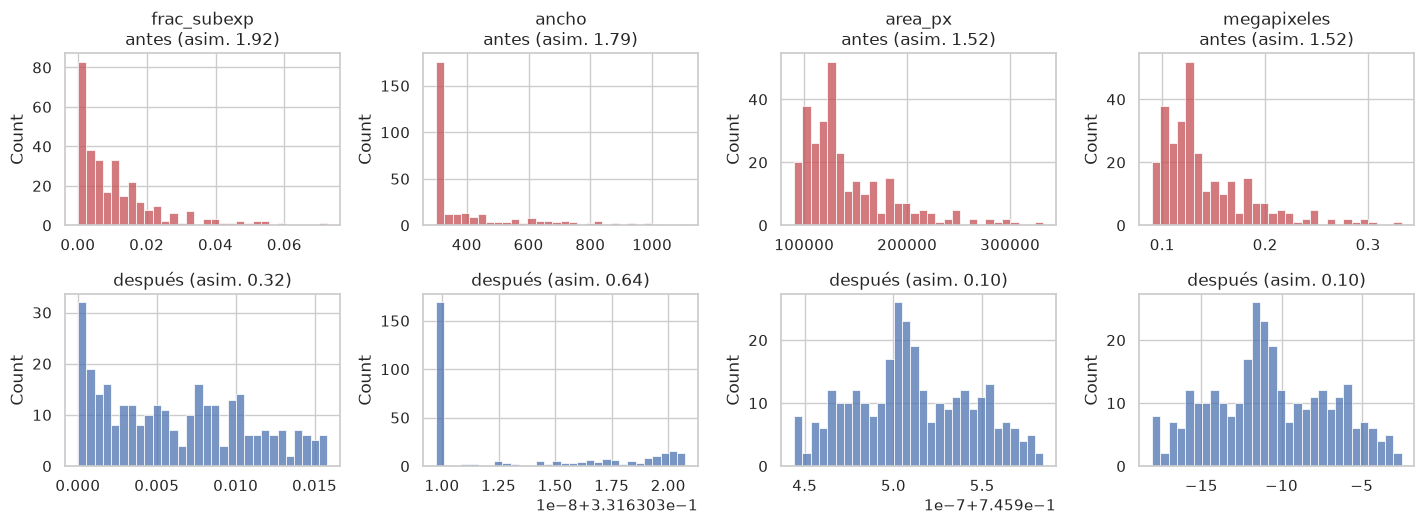

In [12]:
muestra = tabla.reindex(tabla['asimetria_antes'].abs().sort_values(ascending=False).index).index[:4]
fig, axes = plt.subplots(2, len(muestra), figsize=(3.6 * len(muestra), 5.4))
for j, c in enumerate(muestra):
    sns.histplot(Xtr_man[c], ax=axes[0, j], bins=30, color='#C44E52')
    axes[0, j].set(title=f'{c}\nantes (asim. {sesgo[c]:.2f})', xlabel='')
    sns.histplot(desp[c], ax=axes[1, j], bins=30, color='#4C72B0')
    axes[1, j].set(title=f'después (asim. {desp[c].skew():.2f})', xlabel='')
plt.tight_layout(); plt.show()

**Interpretación.** De las 31 variables continuas construidas a mano, 9 tienen asimetría alta: 5 se tratan con Box-Cox y 4 con Yeo-Johnson. La asimetría absoluta media baja de 1.41 a 0.21. El caso más claro es `nitidez_por_borde`: pasa de una asimetría de 1.24 a prácticamente 0, y la prueba de Shapiro-Wilk deja de rechazar la normalidad (p = 0.47). En las demás, la prueba sigue rechazando la normalidad estricta, lo que es esperable con 304 observaciones y variables acotadas como las fracciones de píxeles. El objetivo no es la normalidad perfecta, sino quitar las colas que dominarían a los modelos lineales y a PCA, y eso se cumple. Los valores de λ también confirman el criterio: para el ancho, el alto y el área son negativos (entre −3 y −1.3), es decir, una transformación más fuerte que el logaritmo, adecuada para la cola derecha que dejan los recortes grandes.

## 8. Escalamiento

Las variables tienen escalas muy distintas (el área se mide en cientos de miles de píxeles y los
histogramas en fracciones). Sin escalar, los algoritmos basados en distancia (kNN), en gradiente
(regresión logística) y en varianza (PCA) quedan dominados por las variables de mayor magnitud. Se
comparan tres escaladores ajustados con entrenamiento:

- `StandardScaler` (media 0, varianza 1): adecuado tras la transformación de potencia, cuando las
  variables ya son aproximadamente simétricas; es el que esperan PCA y el análisis factorial.
- `MinMaxScaler` ([0, 1]): conserva la forma de la distribución; necesario para chi-cuadrado, que
  exige valores no negativos.
- `RobustScaler` (mediana y rango intercuartílico): resistente a valores atípicos; útil si no se
  transformaran las colas.

Además se mide el efecto del escalamiento en la **convergencia** de la regresión logística
(iteraciones del optimizador lbfgs) y en la exactitud de kNN.

Variables candidatas para el modelo: 823


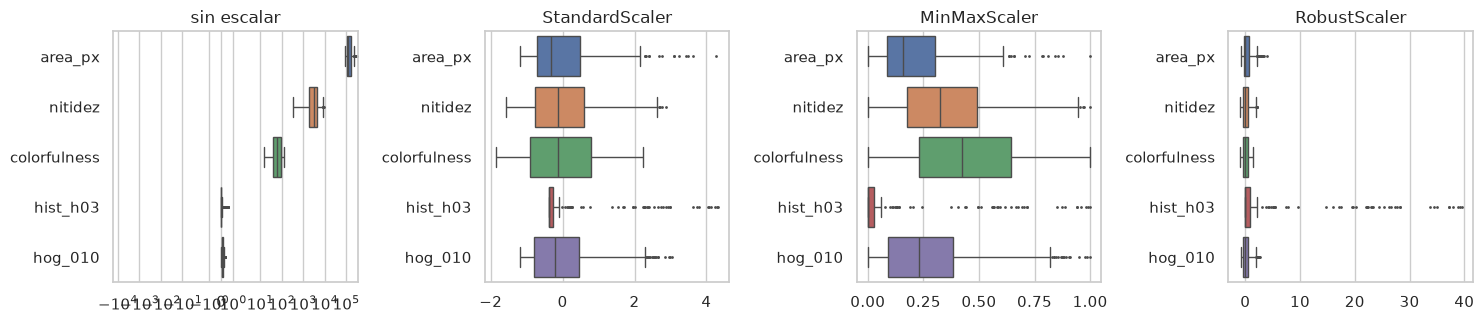

In [13]:
FEATS = MANUALES + FAMILIAS['histogramas HSV'] + FAMILIAS['textura LBP'] + FAMILIAS['forma HOG'] \
        + FLAGS + ['nivel_iluminacion_ord', 'formato_empaque_ord', 'nitidez_q']
X = df_rec[FEATS].astype(float)
X_tr, X_te = X[es_train], X[~es_train]
print('Variables candidatas para el modelo:', X.shape[1])

esc = {'sin escalar': None, 'StandardScaler': StandardScaler(),
       'MinMaxScaler': MinMaxScaler(), 'RobustScaler': RobustScaler()}
ejemplo = ['area_px', 'nitidez', 'colorfulness', 'hist_h03', 'hog_010']
fig, axes = plt.subplots(1, 4, figsize=(15, 3.4))
for ax, (nom, s) in zip(axes, esc.items()):
    Z = X_tr[ejemplo] if s is None else pd.DataFrame(clone(s).fit_transform(X_tr[ejemplo]), columns=ejemplo)
    sns.boxplot(data=Z, ax=ax, orient='h', fliersize=1)
    ax.set(title=nom, xscale='symlog' if s is None else 'linear')
plt.tight_layout(); plt.show()

In [14]:
def potencia():
    return ColumnTransformer([('boxcox', PowerTransformer('box-cox', standardize=False), BOXCOX),
                              ('yeoj', PowerTransformer('yeo-johnson', standardize=False), YEOJ)],
                             remainder='passthrough', verbose_feature_names_out=False)

filas = []
for nom, s in esc.items():
    pasos = [('potencia', potencia())] + ([('escala', clone(s))] if s is not None else [])
    for modelo in ('logistica', 'knn'):
        est = (LogisticRegression(max_iter=5000, random_state=SEED) if modelo == 'logistica'
               else KNeighborsClassifier(n_neighbors=3))
        pipe = Pipeline(pasos + [('clf', est)])
        with warnings.catch_warnings(record=True) as w:
            warnings.simplefilter('always', ConvergenceWarning)
            t0 = time.time(); pipe.fit(X_tr, y_tr); dt = time.time() - t0
        pred = pipe.predict(X_te)
        filas.append({'escalador': nom, 'modelo': modelo,
                      'iteraciones': int(pipe[-1].n_iter_.max()) if modelo == 'logistica' else np.nan,
                      'converge': not any(issubclass(x.category, ConvergenceWarning) for x in w),
                      'seg_ajuste': round(dt, 2),
                      'f1_macro_prueba': round(f1_score(y_te, pred, average='macro'), 3)})
conv = pd.DataFrame(filas)
display(conv.pivot(index='escalador', columns='modelo',
                   values=['f1_macro_prueba', 'iteraciones', 'seg_ajuste']).loc[list(esc)])

f1_macro_prueba           iteraciones           seg_ajuste  \
modelo                     knn logistica         knn logistica        knn   
escalador                                                                   
sin escalar              0.053     0.002         NaN      16.0       0.25   
StandardScaler           0.918     0.973         NaN      12.0       0.23   
MinMaxScaler             0.925     0.973         NaN      60.0       0.25   
RobustScaler             0.964     0.965         NaN      82.0       0.35   

                          
modelo         logistica  
escalador                 
sin escalar         2.37  
StandardScaler      1.54  
MinMaxScaler        7.75  
RobustScaler       12.44

**Interpretación.** El escalamiento es indispensable. Sin escalar, la regresión logística se detiene en 16 iteraciones con un modelo que no aprende (F1 macro de 0.002, por debajo del azar de 1/35 ≈ 0.03) y kNN obtiene 0.053, porque las distancias quedan dominadas por el ancho y el alto en píxeles. Con escalamiento ambos superan 0.91. Entre escaladores, `StandardScaler` logra la convergencia más rápida de la regresión logística (12 iteraciones y 1.7 s, frente a 60 con Min-Max y 82 con Robust) con el mejor F1 (0.973). Es el que se adopta para modelos lineales, PCA y análisis factorial, porque estos métodos suponen variables centradas con varianza comparable. `MinMaxScaler` se conserva solo para chi-cuadrado y el umbral de varianza. `RobustScaler` favorece a kNN (0.964), pero no se adopta: las colas ya se corrigieron con la transformación de potencia.

## 9. Aplicación a las escenas

Las escenas no tienen etiqueta de producto, pero las mismas variables de calidad sirven para
caracterizar las capturas y alimentarán la etapa de detección. Se aplica la misma cadena
(construcción → codificación → transformación → escalamiento) y se verifica con ANOVA de un factor
qué variables de calidad difieren entre tipos de toma.

In [15]:
VAR_ESC = ['megapixeles', 'aspecto', 'kb_por_mp', 'brillo', 'contraste', 'nitidez', 'densidad_bordes',
           'entropia', 'saturacion', 'colorfulness', 'indice_calidad']
anova_esc = pd.DataFrame(
    [dict(zip(['F', 'p'], stats.f_oneway(*[g[v] for _, g in df_esc.groupby('tipo_toma')])))
     for v in VAR_ESC], index=VAR_ESC).sort_values('F', ascending=False)
anova_esc['significativa_0.05'] = anova_esc['p'] < 0.05
display(anova_esc.round(4))

esc_pipe = ColumnTransformer([('yeoj', PowerTransformer('yeo-johnson'), VAR_ESC),
                              ('onehot', 'passthrough', list(esc_ohe.columns))])
Z_esc = esc_pipe.fit_transform(df_esc)
print('Matriz de escenas lista para modelar:', Z_esc.shape)

,F,p,significativa_0.05
aspecto,531.6182,0.0000,True
kb_por_mp,157.8543,0.0000,True
nitidez,86.7308,0.0000,True
megapixeles,78.4579,0.0000,True
indice_calidad,38.0727,0.0000,True
entropia,31.1781,0.0000,True
colorfulness,21.8239,0.0000,True
contraste,17.5311,0.0000,True
brillo,12.6646,0.0000,True
saturacion,10.1380,0.0000,True


Matriz de escenas lista para modelar: (100, 16)


# B. Selección y extracción de características

Con 422 recortes y más de 850 variables candidatas (la mayoría de HOG), el problema tiene más
dimensiones que observaciones. Reducirlas disminuye almacenamiento y tiempo de entrenamiento, el
riesgo de sobreajuste y facilita interpretar qué rasgos distinguen a los productos. Se aplican filtros
en cascada, del más barato al más informativo, y cada decisión se valida con la exactitud de un
modelo base (regresión logística) en validación cruzada por bloques sobre entrenamiento.

## 10. Umbral de varianza

Una variable casi constante no puede separar clases. Como la varianza depende de la escala, el umbral
se aplica después de `MinMaxScaler` (todas las variables en [0, 1]); un umbral de 0.001 equivale a una
desviación estándar menor a 3 % del rango.

Eliminadas por baja varianza: 2 de 823
{'construidas/ordinales': 2}


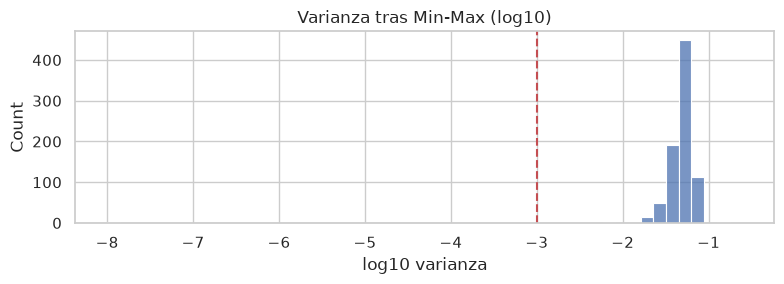

In [16]:
mm = MinMaxScaler().fit(X_tr)
vt = VarianceThreshold(threshold=1e-3).fit(mm.transform(X_tr))
var_mm = pd.Series(vt.variances_, index=FEATS)
baja_var = var_mm[~vt.get_support()].index.tolist()
fam_de = {c: f for f, cols in FAMILIAS.items() for c in cols}
print(f'Eliminadas por baja varianza: {len(baja_var)} de {len(FEATS)}')
print(pd.Series([fam_de.get(c, 'construidas/ordinales') for c in baja_var]).value_counts().to_dict())
fig, ax = plt.subplots(figsize=(8, 3))
sns.histplot(np.log10(var_mm + 1e-8), bins=50, ax=ax)
ax.axvline(-3, c='r', ls='--'); ax.set(title='Varianza tras Min-Max (log10)', xlabel='log10 varianza')
plt.tight_layout(); plt.show()

## 11. Correlación

Dos variables con correlación |r| > 0.95 aportan prácticamente la misma información; conservar ambas
duplica peso en el modelo y vuelve inestables los coeficientes. Se calcula la correlación de Spearman
(robusta a relaciones monótonas no lineales) sobre entrenamiento y, de cada par, se elimina la variable
con mayor correlación media con el resto.

Eliminadas por redundancia (|rho| > 0.95): 305 -> quedan 516
Ejemplos: ['area_px', 'aspecto', 'brillo', 'contraste', 'nitidez', 'exposicion_ok', 'hog_011', 'hog_012', 'hog_014', 'hog_021', 'hog_023', 'hog_024']


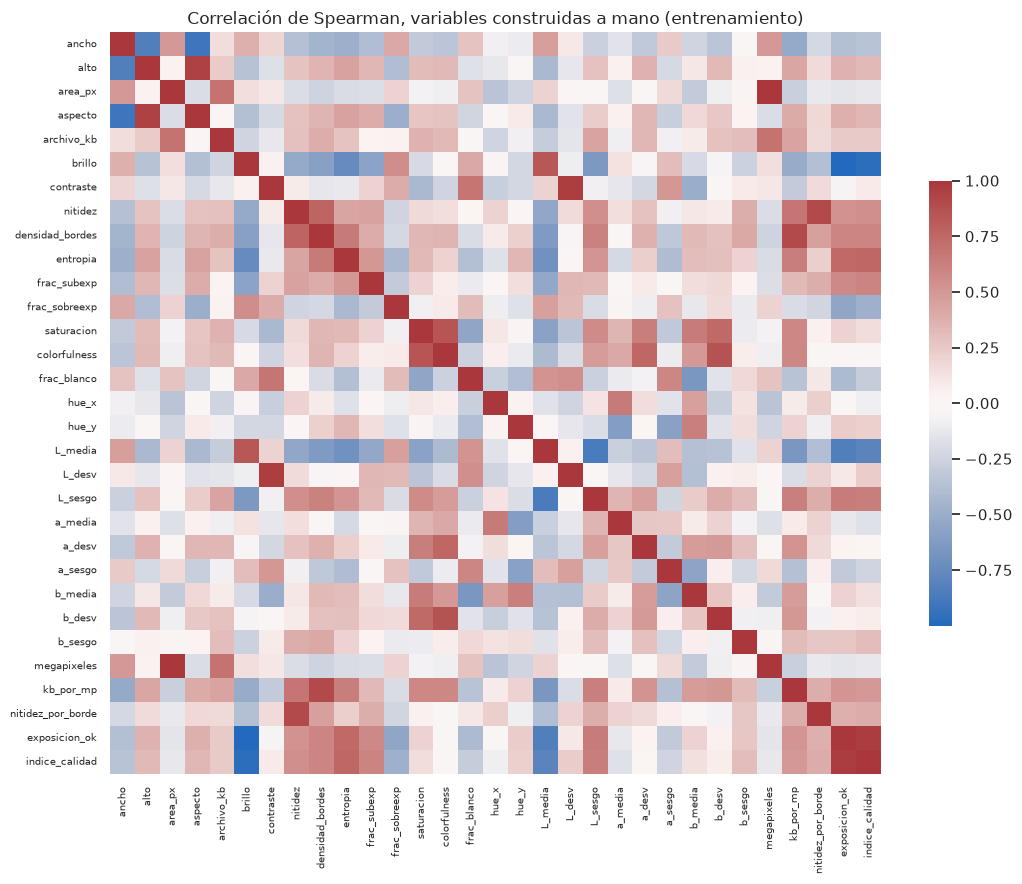

In [17]:
class FiltroCorrelacion(BaseEstimator, TransformerMixin):
    def __init__(self, umbral=0.95):
        self.umbral = umbral
    def fit(self, X, y=None):
        C = pd.DataFrame(X).corr(method='spearman').abs().fillna(0).to_numpy(copy=True)
        np.fill_diagonal(C, 0)
        quitar, media = set(), C.mean(axis=0)
        for i, j in zip(*np.where(np.triu(C) > self.umbral)):
            if i in quitar or j in quitar: continue
            quitar.add(i if media[i] >= media[j] else j)
        self.mantener_ = np.array([k not in quitar for k in range(C.shape[0])])
        return self
    def transform(self, X):
        return np.asarray(X)[:, self.mantener_]
    def get_support(self):
        return self.mantener_

tras_var = [c for c in FEATS if c not in baja_var]
fc = FiltroCorrelacion(0.95).fit(X_tr[tras_var])
redund = [c for c, k in zip(tras_var, fc.get_support()) if not k]
print(f'Eliminadas por redundancia (|rho| > 0.95): {len(redund)} -> quedan {fc.get_support().sum()}')
print('Ejemplos:', redund[:12])

man = [c for c in MANUALES + NUEVAS if c in tras_var]
man = list(dict.fromkeys(man))
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(X_tr[man].corr(method='spearman'), cmap='vlag', center=0, ax=ax,
            xticklabels=True, yticklabels=True, cbar_kws={'shrink': .6})
ax.set_title('Correlación de Spearman, variables construidas a mano (entrenamiento)')
ax.tick_params(labelsize=7); plt.tight_layout(); plt.show()

## 12. Relevancia respecto al SKU: ANOVA, chi-cuadrado e información mutua

Se ordenan las variables restantes por su relación con la clase:

- **ANOVA F** (`f_classif`): compara la varianza entre clases contra la varianza dentro de clases;
  apropiada para variables continuas y objetivo categórico, y detecta diferencias de medias.
- **Chi-cuadrado** (`chi2`): mide la dependencia entre una variable no negativa (conteos o
  frecuencias) y la clase. Aplica de forma natural a los histogramas HSV, LBP y HOG (proporciones) y a
  las variables discretizadas; para las continuas se usan sus valores Min-Max.
- **Información mutua**: capta dependencias no lineales que ANOVA no ve; se usa como contraste.

Después se elige cuántas variables conservar (*k*) con la curva de validación cruzada.

In [18]:
cand = [c for c, k in zip(tras_var, fc.get_support()) if k]
Xtr_c = X_tr[cand]
pre_c = Pipeline([('potencia', ColumnTransformer(
            [('boxcox', PowerTransformer('box-cox', standardize=False), [c for c in BOXCOX if c in cand]),
             ('yeoj', PowerTransformer('yeo-johnson', standardize=False), [c for c in YEOJ if c in cand])],
            remainder='passthrough', verbose_feature_names_out=False)),
                  ('escala', StandardScaler())])
Ztr = pre_c.fit_transform(Xtr_c)
nombres_z = list(pre_c[0].get_feature_names_out())

F, pF = f_classif(Ztr, y_tr)
C2, pC = chi2(MinMaxScaler().fit_transform(Xtr_c[nombres_z]), y_tr)
MI = mutual_info_classif(Ztr, y_tr, random_state=SEED)
rel = pd.DataFrame({'F_anova': F, 'p_anova': pF, 'chi2': C2, 'p_chi2': pC, 'info_mutua': MI},
                   index=nombres_z)
rel['familia'] = [fam_de.get(c, 'construidas/ordinales') for c in rel.index]
for m in ('F_anova', 'chi2', 'info_mutua'):
    rel[f'rango_{m}'] = rel[m].rank(ascending=False)
display(rel.sort_values('F_anova', ascending=False).head(15).round(4))
print('Variables significativas (p < 0.05): ANOVA', int((rel.p_anova < .05).sum()),
      '| chi2', int((rel.p_chi2 < .05).sum()), 'de', len(rel))
print('Correlación de Spearman entre rankings:')
display(rel[['rango_F_anova', 'rango_chi2', 'rango_info_mutua']].corr(method='spearman').round(2))

,F_anova,p_anova,chi2,p_chi2,info_mutua,familia,rango_F_anova,rango_chi2,rango_info_mutua
hist_h03,666.0374,0.0,163.6822,0.0000,1.7465,histogramas HSV,1.0,2.0,9.0
hist_h07,324.4703,0.0,134.0175,0.0000,1.6652,histogramas HSV,2.0,5.0,12.0
hue_x,322.2371,0.0,35.9922,0.3754,1.8977,color global,3.0,28.0,5.0
hist_h01,309.4108,0.0,62.4344,0.0021,1.9344,histogramas HSV,4.0,13.0,4.0
a_media,295.7376,0.0,15.7202,0.9969,1.9922,color global,5.0,350.0,3.0
hist_h06,234.3505,0.0,169.9416,0.0000,1.2781,histogramas HSV,6.0,1.0,28.0
hue_y,233.3921,0.0,32.5537,0.5385,1.8308,color global,7.0,33.0,6.0
hist_h02,188.7103,0.0,90.6286,0.0000,1.3559,histogramas HSV,8.0,9.0,25.0
saturacion,153.6491,0.0,46.6307,0.0730,1.5751,color global,9.0,18.0,16.0
a_desv,147.4383,0.0,43.1494,0.1351,1.7431,color global,10.0,20.0,10.0


Variables significativas (p < 0.05): ANOVA 516 | chi2 17 de 516
Correlación de Spearman entre rankings:


,rango_F_anova,rango_chi2,rango_info_mutua
rango_F_anova,1.00,0.64,0.70
rango_chi2,0.64,1.00,0.33
rango_info_mutua,0.70,0.33,1.00


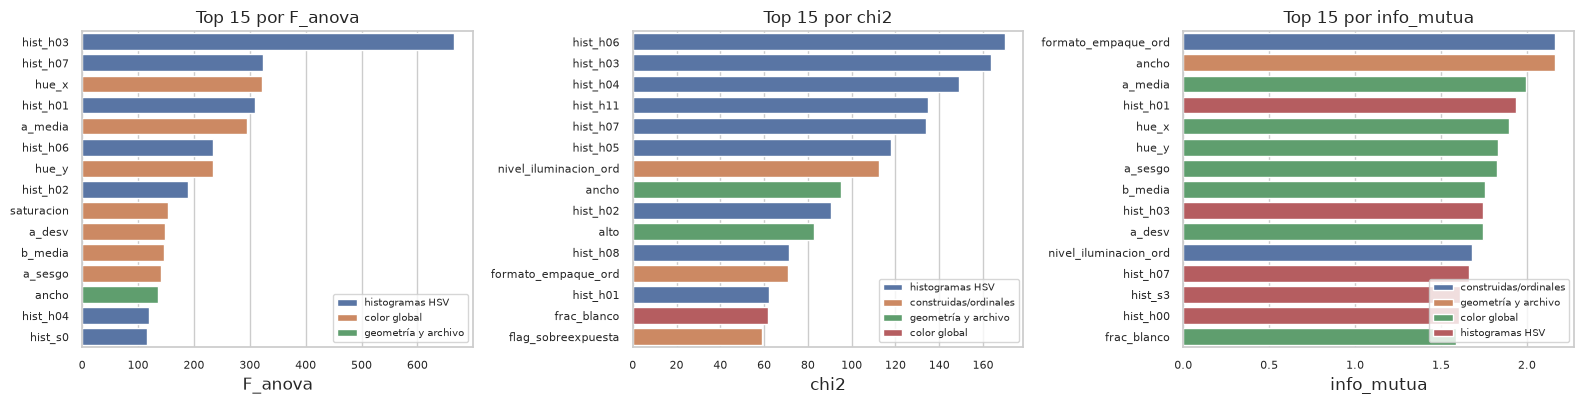

Composición de las 100 variables con mayor F: {'forma HOG': 49, 'histogramas HSV': 17, 'color global': 14, 'textura LBP': 10, 'construidas/ordinales': 4, 'geometría y archivo': 3, 'exposición y calidad': 3}


In [19]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, m in zip(axes, ('F_anova', 'chi2', 'info_mutua')):
    top = rel.sort_values(m, ascending=False).head(15)
    sns.barplot(x=top[m], y=top.index, hue=top['familia'], dodge=False, ax=ax)
    ax.set(title=f'Top 15 por {m}', ylabel=''); ax.tick_params(labelsize=8)
    ax.legend(fontsize=7, loc='lower right')
plt.tight_layout(); plt.show()
top100 = rel.sort_values('F_anova', ascending=False).head(100)['familia'].value_counts()
print('Composición de las 100 variables con mayor F:', top100.to_dict())

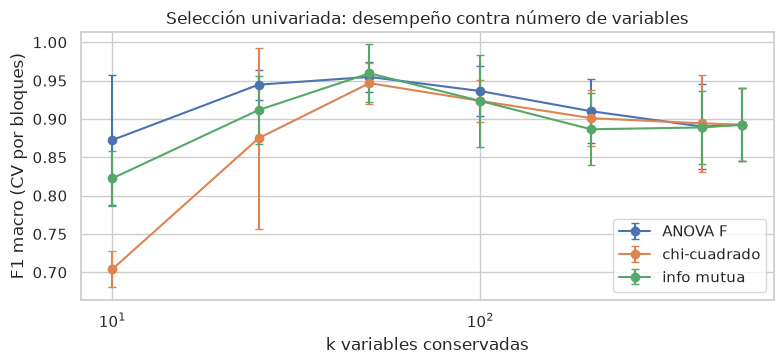

criterio,ANOVA F,chi-cuadrado,info mutua
k,,,
10,0.872,0.704,0.822
25,0.945,0.875,0.912
50,0.955,0.947,0.960
100,0.936,0.924,0.923
200,0.910,0.901,0.887
400,0.890,0.894,0.889
516,0.893,0.893,0.893


In [20]:
def pipe_base(selector=None, extractor=None, columnas=None):
    cols = columnas or cand
    pasos = [('potencia', ColumnTransformer(
                [('boxcox', PowerTransformer('box-cox', standardize=False), [c for c in BOXCOX if c in cols]),
                 ('yeoj', PowerTransformer('yeo-johnson', standardize=False), [c for c in YEOJ if c in cols])],
                remainder='passthrough', verbose_feature_names_out=False)),
             ('escala', StandardScaler())]
    if selector is not None: pasos.append(('seleccion', selector))
    if extractor is not None: pasos.append(('extraccion', extractor))
    pasos.append(('clf', LogisticRegression(max_iter=5000, random_state=SEED)))
    return Pipeline(pasos)

def cv_f1(pipe, Xd):
    return cross_val_score(pipe, Xd, y_tr, groups=g_tr, cv=CV, scoring='f1_macro')

KS = [10, 25, 50, 100, 200, 400, len(cand)]
# Los puntajes se calculan una vez por pliegue (solo con su parte de entrenamiento) y se reutilizan
# para cada k; equivale a SelectKBest dentro del pipeline sin recalcular la información mutua.
curva = []
for f_tr, f_va in CV.split(Xtr_c, y_tr, g_tr):
    Xa, Xb, ya, yb = Xtr_c.iloc[f_tr], Xtr_c.iloc[f_va], y_tr[f_tr], y_tr[f_va]
    pre = clone(pre_c).fit(Xa)
    Za, Zb = pre.transform(Xa), pre.transform(Xb)
    mm_f = MinMaxScaler().fit(Xa[nombres_z])
    puntajes = {'ANOVA F': f_classif(Za, ya)[0],
                'chi-cuadrado': chi2(mm_f.transform(Xa[nombres_z]), ya)[0],
                'info mutua': mutual_info_classif(Za, ya, random_state=SEED)}
    for nom, sc in puntajes.items():
        orden = np.argsort(np.nan_to_num(sc, nan=-1))[::-1]
        for k in KS:
            idx = orden[:k]
            clf = LogisticRegression(max_iter=5000, random_state=SEED).fit(Za[:, idx], ya)
            curva.append({'criterio': nom, 'k': k,
                          'f1': f1_score(yb, clf.predict(Zb[:, idx]), average='macro')})
curva = (pd.DataFrame(curva).groupby(['criterio', 'k'])['f1']
         .agg(f1_cv='mean', desv='std').reset_index())
fig, ax = plt.subplots(figsize=(8, 3.8))
for nom, g in curva.groupby('criterio'):
    ax.errorbar(g['k'], g['f1_cv'], yerr=g['desv'], marker='o', capsize=3, label=nom)
ax.set(xscale='log', xlabel='k variables conservadas', ylabel='F1 macro (CV por bloques)',
       title='Selección univariada: desempeño contra número de variables')
ax.legend(); plt.tight_layout(); plt.show()
display(curva.pivot(index='k', columns='criterio', values='f1_cv').round(3))

**Interpretación.** El umbral de varianza apenas elimina 2 variables (indicadores constantes: ningún recorte quedó oscuro ni borroso). En cambio, el filtro de correlación descarta 305 de 821, sobre todo celdas HOG vecinas, que comparten bordes, y variables construidas que repiten información, como `area_px` y `megapixeles`, o `brillo` y `exposicion_ok`. Quedan 516 candidatas. ANOVA ordena primero el color: el histograma de matiz, los componentes de Lab y `hue_x`/`hue_y`. Entre las 100 variables con mayor F hay 49 de HOG, así que la forma también aporta. Chi-cuadrado coincide parcialmente con ANOVA (ρ = 0.64) y declara significativas solo 17 variables, porque supone frecuencias y solo los histogramas lo son. Por eso funciona bien en los histogramas de matiz y mal en las continuas, como `a_media`. La información mutua coincide más con ANOVA (ρ = 0.70). La curva de validación muestra un máximo claro con pocas variables: ANOVA con k = 50 alcanza F1 = 0.955 ± 0.016, por encima de usar las 516 (0.893). Con más variables el modelo empieza a sobreajustar las 304 observaciones de entrenamiento.

## 13. Extracción: análisis de componentes principales (PCA)

PCA proyecta las variables estandarizadas en direcciones ortogonales de máxima varianza. Es útil aquí
porque el bloque HOG contiene cientos de variables correlacionadas entre sí (celdas vecinas comparten
bordes). Se ajusta con entrenamiento y se reportan los componentes necesarios para retener 90 % y 95 %
de la varianza.

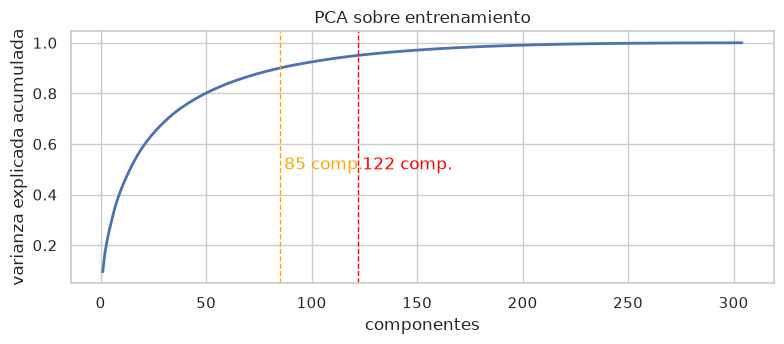

516 variables -> 85 componentes (90 %) / 122 componentes (95 %)


In [21]:
pca_full = PCA(random_state=SEED).fit(Ztr)
acum = np.cumsum(pca_full.explained_variance_ratio_)
n90, n95 = int(np.searchsorted(acum, 0.90) + 1), int(np.searchsorted(acum, 0.95) + 1)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(range(1, len(acum) + 1), acum, lw=2)
for n, c in ((n90, 'orange'), (n95, 'red')):
    ax.axvline(n, ls='--', c=c, lw=1); ax.text(n + 2, 0.5, f'{n} comp.', color=c)
ax.set(xlabel='componentes', ylabel='varianza explicada acumulada', title='PCA sobre entrenamiento')
plt.tight_layout(); plt.show()
print(f'{len(nombres_z)} variables -> {n90} componentes (90 %) / {n95} componentes (95 %)')

## 14. Extracción: análisis factorial (FA)

A diferencia de PCA, el análisis factorial modela las variables como combinación de pocos **factores
latentes** más ruido propio de cada variable, y con una rotación varimax produce cargas
interpretables. Se aplica a las variables construidas a mano (geometría, exposición, color), donde
interesa entender qué dimensiones subyacentes describen un recorte; aplicarlo a cientos de variables
HOG con 300 observaciones no sería estable.

Antes se verifica que los datos sean factorizables con la prueba de esfericidad de Bartlett (la matriz
de correlación no debe ser la identidad) y el índice KMO (Kaiser, 1974; valores ≥ 0.6 se consideran
aceptables). El número de factores se elige con el criterio de Kaiser (autovalores > 1).

Bartlett: chi2 = 9258.7, p = 0.00e+00 | KMO global = 0.694 | factores (Kaiser) = 6 de 23 variables


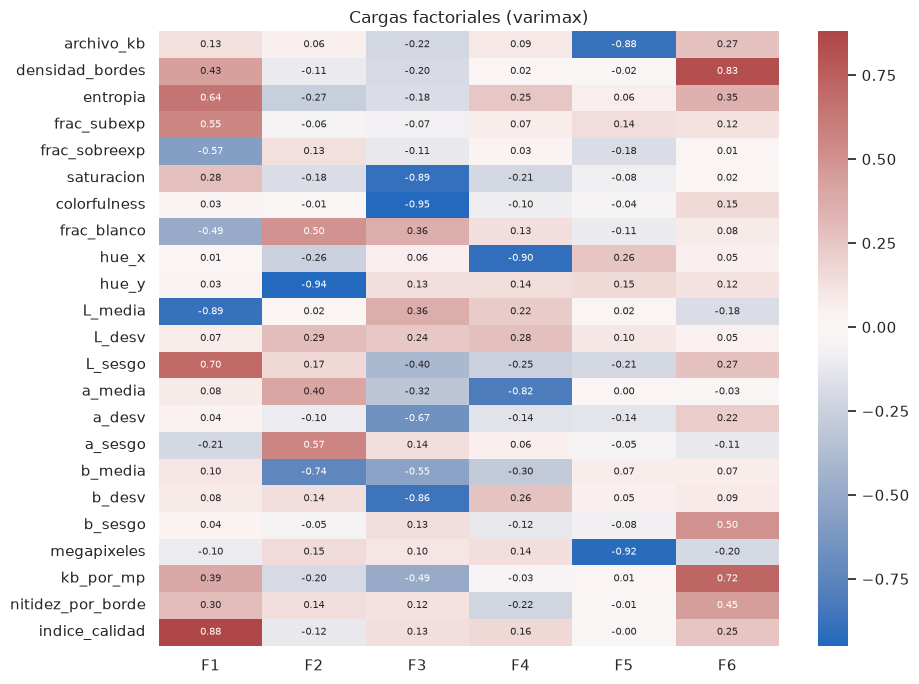

Variable dominante por factor:
  F1: ['L_media', 'indice_calidad', 'L_sesgo']
  F2: ['hue_y', 'b_media', 'a_sesgo']
  F3: ['colorfulness', 'saturacion', 'b_desv']
  F4: ['hue_x', 'a_media', 'b_media']
  F5: ['megapixeles', 'archivo_kb', 'hue_x']
  F6: ['densidad_bordes', 'kb_por_mp', 'b_sesgo']


In [22]:
man_c = [c for c in MANUALES if c in cand and c not in ('ancho', 'alto')]
Zman = pd.DataFrame(Ztr, columns=nombres_z)[man_c]
chi_b, p_b = calculate_bartlett_sphericity(Zman)
with warnings.catch_warnings():
    # Aviso de matriz casi singular por variables construidas como combinación de otras;
    # la librería usa la pseudoinversa (ver interpretación).
    warnings.simplefilter('ignore', UserWarning)
    kmo_var, kmo_tot = calculate_kmo(Zman)
autoval = np.linalg.eigvalsh(np.corrcoef(Zman.T))[::-1]
n_fact = int((autoval > 1).sum())
print(f'Bartlett: chi2 = {chi_b:.1f}, p = {p_b:.2e} | KMO global = {kmo_tot:.3f} | '
      f'factores (Kaiser) = {n_fact} de {len(man_c)} variables')

fa = FactorAnalysis(n_components=n_fact, rotation='varimax', random_state=SEED).fit(Zman)
cargas = pd.DataFrame(fa.components_.T, index=man_c, columns=[f'F{i+1}' for i in range(n_fact)])
fig, ax = plt.subplots(figsize=(1.1 * n_fact + 3, 7))
sns.heatmap(cargas, cmap='vlag', center=0, annot=True, fmt='.2f', annot_kws={'size': 7}, ax=ax)
ax.set_title('Cargas factoriales (varimax)'); plt.tight_layout(); plt.show()
print('Variable dominante por factor:')
for f in cargas:
    top = cargas[f].abs().sort_values(ascending=False).head(3).index.tolist()
    print(f'  {f}: {top}')

**Interpretación.** PCA necesita 85 componentes para el 90 % de la varianza y 122 para el 95 %: comprime 516 variables a una cuarta parte, pero los componentes no son interpretables. El análisis factorial sobre las 23 variables manuales es factorizable: la prueba de Bartlett rechaza la matriz identidad (p < 0.001) y el KMO global es 0.69, aceptable según Kaiser (1974). El criterio de Kaiser retiene 6 factores con una lectura clara: F1 luminosidad y calidad de captura (L medio, índice de calidad), F2 eje amarillo-azul del color, F3 intensidad cromática (*colorfulness*, saturación), F4 eje rojo-verde, F5 resolución y peso del archivo, y F6 detalle y textura (densidad de bordes, KB por megapíxel). El aviso de matriz casi singular se debe a que algunas variables construidas son combinación determinista de otras (por ejemplo, el índice de calidad y la exposición). Se resolvió con la pseudoinversa y confirma la redundancia que ya había detectado el filtro de correlación.

## 15. Comparativa de configuraciones y elección

Se comparan las configuraciones con el mismo modelo base y la misma validación. La regresión logística
sobre las variables completamente crudas no se incluye: con el área en cientos de miles de píxeles el
optimizador no terminó en un tiempo razonable, lo que por sí mismo confirma la necesidad de transformar
y escalar. Las métricas de
prueba se calculan una sola vez por configuración sobre el bloque temporal final de cada SKU; la
elección se basa en la validación cruzada, no en la prueba.

In [23]:
k_anova = int(curva[curva.criterio == 'ANOVA F'].sort_values('f1_cv', ascending=False).iloc[0]['k'])
k_anova = min(k_anova, len(cand))
CONFIGS = {
    '1. todas, potencia sin escalar': (Pipeline([('potencia', potencia()), ('clf', LogisticRegression(max_iter=5000, random_state=SEED))]), FEATS),
    '2. todas, potencia + estándar': (pipe_base(columnas=FEATS), FEATS),
    '3. + varianza + correlación': (pipe_base(), cand),
    f'4. + ANOVA (k={k_anova})': (pipe_base(SelectKBest(f_classif, k=k_anova)), cand),
    f'5. PCA 95 % ({n95} comp.)': (pipe_base(extractor=PCA(n_components=0.95, random_state=SEED)), cand),
    f'6. solo manuales ({len(man_c)})': (pipe_base(columnas=man_c), man_c),
    f'7. factores FA ({n_fact})': (pipe_base(extractor=FactorAnalysis(n_components=n_fact, rotation='varimax', random_state=SEED), columnas=man_c), man_c),
}
filas = []
for nom, (p, cols) in CONFIGS.items():
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', ConvergenceWarning)
        s = cv_f1(p, X_tr[cols])
        t0 = time.time(); p.fit(X_tr[cols], y_tr); dt = time.time() - t0
    pred = p.predict(X_te[cols])
    n_out = p[:-1].transform(X_tr[cols].iloc[:2]).shape[1] if len(p) > 1 else len(cols)
    filas.append({'configuración': nom, 'variables al modelo': n_out,
                  'F1 CV': s.mean(), 'F1 CV desv': s.std(),
                  'F1 prueba': f1_score(y_te, pred, average='macro'),
                  'exactitud prueba': accuracy_score(y_te, pred),
                  'iteraciones': int(p[-1].n_iter_.max()), 'seg ajuste': dt})
comp = pd.DataFrame(filas).set_index('configuración')
display(comp.round(3))

,variables al modelo,F1 CV,F1 CV desv,F1 prueba,exactitud prueba,iteraciones,seg ajuste
configuración,,,,,,,
"1. todas, potencia sin escalar",823,0.002,0.000,0.002,0.034,16,2.404
"2. todas, potencia + estándar",823,0.882,0.034,0.973,0.975,12,2.103
3. + varianza + correlación,516,0.893,0.039,0.964,0.966,14,1.681
4. + ANOVA (k=50),50,0.955,0.016,0.976,0.975,54,0.273
5. PCA 95 % (122 comp.),122,0.887,0.047,0.964,0.966,17,0.371
6. solo manuales (23),23,0.904,0.022,0.927,0.932,64,0.212
7. factores FA (6),6,0.812,0.044,0.821,0.831,29,0.282


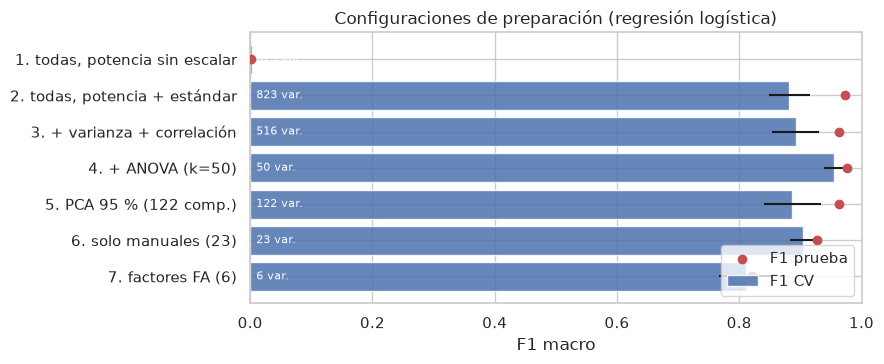

In [24]:
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.barh(comp.index[::-1], comp['F1 CV'][::-1], xerr=comp['F1 CV desv'][::-1], color='#4C72B0',
        label='F1 CV', alpha=.85)
ax.scatter(comp['F1 prueba'][::-1], comp.index[::-1], color='#C44E52', zorder=3, label='F1 prueba')
for i, (n, v) in enumerate(comp['variables al modelo'][::-1].items()):
    ax.text(0.01, i, f'{v} var.', va='center', color='white', fontsize=8)
ax.set(xlabel='F1 macro', xlim=(0, 1), title='Configuraciones de preparación (regresión logística)')
ax.legend(loc='lower right'); plt.tight_layout(); plt.show()

**Interpretación.** La configuración 4 (transformación de potencia, estandarización, filtros de varianza y correlación, y ANOVA con k = 50) es la mejor en validación cruzada (F1 = 0.955 ± 0.016) y la más estable, y lo confirma en prueba (F1 = 0.976). Usa 50 de 823 variables (6 %) y se entrena 5.5 veces más rápido que el conjunto completo (0.28 s contra 1.53 s). PCA iguala el desempeño del conjunto completo con 122 componentes, pero no mejora la validación cruzada y sacrifica la interpretación. Las 23 variables manuales (0.904) y sobre todo los 6 factores (0.812) pierden exactitud, pero muestran que con muy pocas dimensiones interpretables ya se distingue la mayoría de los productos. Los factores son útiles para explicar el modelo, no para sustituirlo. La configuración 1 confirma otra vez que sin escalamiento el modelo no aprende. **Se elige la configuración 4.**

## 16. Pipeline final y persistencia

El pipeline elegido se ajusta con entrenamiento y se guarda junto con la tabla de características en
`PLANOGRAMA_OUT_DIR`, dentro de la infraestructura de Bnext. Ambos archivos quedan fuera del
repositorio (`.gitignore`), conforme a la política de datos.

In [25]:
ELEGIDA = next(n for n in CONFIGS if n.startswith(os.environ.get('AVANCE2_ELEGIDA', '4.')))
final, cols_final = CONFIGS[ELEGIDA]
final = clone(final).fit(X_tr[cols_final], y_tr)
joblib.dump({'pipeline': final, 'columnas': cols_final, 'clases': list(le.classes_)},
            OUT_DIR / 'avance2_pipeline.joblib')
df_rec.drop(columns=['orden', 'n_sku']).assign(particion=np.where(es_train, 'train', 'test')) \
      .to_csv(OUT_DIR / 'avance2_caracteristicas_recortes.csv', index=False)
df_esc.to_csv(OUT_DIR / 'avance2_caracteristicas_escenas.csv', index=False)
print('Configuración elegida:', ELEGIDA)
print('Archivos generados:', sorted(p.name for p in OUT_DIR.glob('avance2_*')))

Configuración elegida: 4. + ANOVA (k=50)
Archivos generados: ['avance2_caracteristicas_escenas.csv', 'avance2_caracteristicas_recortes.csv', 'avance2_pipeline.joblib']


# C. Conclusiones de la fase de Preparación de los datos (CRISP-ML(Q))

En CRISP-ML(Q), la preparación de los datos abarca la selección, la limpieza, la construcción y la estandarización de las variables, con aseguramiento de calidad en cada paso (Visengeriyeva et al., 2023). El balance de este avance es el siguiente.

1. **Selección de datos.** Se trabajó con la muestra real entregada por Bnext dentro de su infraestructura: 100 escenas en cinco tipos de toma y 422 recortes de 35 SKU. Los recortes son el único subconjunto etiquetado, así que en ellos se validaron las decisiones. La razón de desbalance es moderada (2.4x) y no requiere remuestreo en esta etapa.
2. **Limpieza y calidad.** No hay valores faltantes. Los indicadores de calidad muestran que las capturas son nítidas y bien iluminadas. El umbral de sobreexposición se activa en 56 % de los recortes por los empaques blancos, así que debe recalibrarse por producto. Se descartó `fuente_captura` por fuga de información: identifica la clase y no existirá en producción.
3. **Construcción.** Se pasó de píxeles a 823 variables con significado visual (geometría, exposición, color, textura LBP y forma HOG). Se añadieron variables de dominio: índice de calidad, KB por megapíxel, nitidez normalizada, matiz circular y alertas de captura. También se discretizaron la iluminación, el formato de empaque y la nitidez, y se codificaron el tipo de toma (*one-hot*), las variables ordinales y el SKU.
4. **Estandarización.** La transformación de potencia (Box-Cox y Yeo-Johnson) redujo la asimetría absoluta media de 1.41 a 0.21. La estandarización hizo posible que la regresión logística converja en 12 iteraciones y elevó kNN de 0.05 a 0.92 de F1.
5. **Reducción.** Los filtros de varianza y correlación eliminaron 307 variables redundantes. ANOVA con k = 50 dejó un conjunto de 50 variables (6 % del original) que mejora la validación cruzada (0.955 contra 0.882) y reduce el tiempo de entrenamiento 5.5 veces. PCA y el análisis factorial se documentaron como alternativas: el segundo aporta seis dimensiones interpretables que servirán para explicar los errores del modelo.
6. **Aseguramiento de calidad.** Todas las transformaciones se ajustaron solo con entrenamiento, dentro de un `Pipeline`. La partición por bloques temporales evita que fotos tomadas en la misma ráfaga queden en ambos lados, que fue el riesgo principal identificado en el Avance 1. La semilla está fija, y el pipeline y las tablas de características quedan versionados en el servidor de Bnext.

**Riesgos que pasan a la fase de modelado:**

- La muestra es pequeña (304 recortes de entrenamiento) y cada SKU proviene de una sola sesión de captura. Por eso las métricas altas obtenidas aquí miden la separabilidad de los productos, no la generalización a otras tiendas, otras fechas u otros dispositivos.
- El Avance 1 trabajó con datos sintéticos. Este avance es el primero sobre datos reales, y confirma que el color es la señal dominante, como anticipaba el EDA.
- Las características diseñadas a mano sirven como línea base interpretable. La detección en anaquel completo requerirá modelos de aprendizaje profundo (detectores de objetos) que aprenden sus propias características; las variables de calidad y el pipeline de este avance se reutilizarán para filtrar capturas y para explicar errores.

**Siguiente fase (Ingeniería del modelo):** entrenar modelos de clasificación y detección sobre la partición definida, comparar contra la línea base de la configuración 4 y solicitar a Bnext más sesiones de captura por SKU para validar la generalización.

## Referencias

Box, G. E. P., y Cox, D. R. (1964). An analysis of transformations. *Journal of the Royal Statistical
Society: Series B (Methodological), 26*(2), 211–252. https://doi.org/10.1111/j.2517-6161.1964.tb00553.x

Dalal, N., y Triggs, B. (2005). Histograms of oriented gradients for human detection. En *2005 IEEE
Computer Society Conference on Computer Vision and Pattern Recognition* (Vol. 1, pp. 886–893). IEEE.
https://doi.org/10.1109/CVPR.2005.177

Galli, S. (2022). *Python feature engineering cookbook* (2a ed.). Packt Publishing.

Hasler, D., y Süsstrunk, S. (2003). Measuring colourfulness in natural images. En *Human Vision and
Electronic Imaging VIII* (Vol. 5007, pp. 87–95). SPIE. https://doi.org/10.1117/12.477378

Kaiser, H. F. (1974). An index of factorial simplicity. *Psychometrika, 39*(1), 31–36.
https://doi.org/10.1007/BF02291575

Ojala, T., Pietikäinen, M., y Mäenpää, T. (2002). Multiresolution gray-scale and rotation invariant
texture classification with local binary patterns. *IEEE Transactions on Pattern Analysis and Machine
Intelligence, 24*(7), 971–987. https://doi.org/10.1109/TPAMI.2002.1017623

Pech-Pacheco, J. L., Cristóbal, G., Chamorro-Martínez, J., y Fernández-Valdivia, J. (2000). Diatom
autofocusing in brightfield microscopy: A comparative study. En *Proceedings 15th International
Conference on Pattern Recognition* (Vol. 3, pp. 314–317). IEEE. https://doi.org/10.1109/ICPR.2000.903548

Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M.,
Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M.,
Perrot, M., y Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine
Learning Research, 12*, 2825–2830.

Visengeriyeva, L., Kammer, A., Bär, I., Kniesz, A., y Plöd, M. (2023). *CRISP-ML(Q). The ML lifecycle
process*. MLOps. INNOQ. https://ml-ops.org/content/crisp-ml

Yeo, I.-K., y Johnson, R. A. (2000). A new family of power transformations to improve normality or
symmetry. *Biometrika, 87*(4), 954–959. https://doi.org/10.1093/biomet/87.4.954